In [1]:
import numpy as np
import matplotlib.pyplot as plt
import bordado as bd 
import srtomo

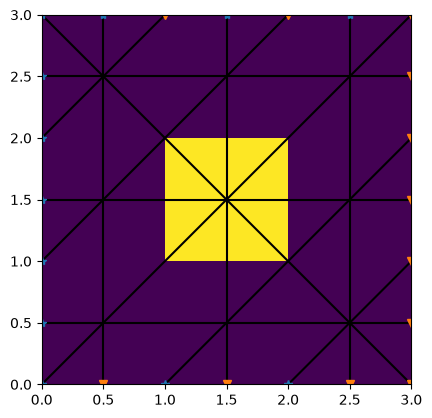

In [2]:
region = [0, 3, 0, 3]
spacing = 1
grid = bd.grid_coordinates(region, spacing=spacing, pixel_register=True)
shape = grid[0].shape
true_p = np.ones(grid[0].shape)
true_p[1,1] = 4
true_p = true_p.ravel()
sources = (
    np.array([0, 0, 0, 0.5, 1.5, 2.5, 0, 2, 1, 0, 0, 0]), # coordenadas x das fontes
    np.array([0.5, 1.5, 2.5, 3, 3, 3, 3, 0, 0, 0, 1, 2]), # cordenadas y das fontes
)

recivers = (
    np.array([3, 3, 3, 0.5, 1.5, 2.5, 3, 3, 3, 3, 2, 1]),
    np.array([0.5, 1.5, 2.5, 0, 0, 0, 0, 1, 2, 3, 3, 3]),
)

plt.imshow(true_p.reshape(shape), extent=region)
plt.plot(sources[0], sources[1], '*')
plt.plot(recivers[0], recivers[1], 'v')
srtomo.plot_ray_paths(sources, recivers, zorder=0)

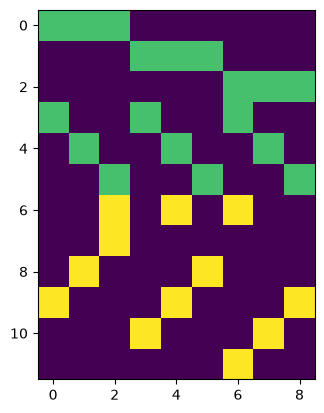

In [3]:
G = srtomo.jacobian(sources, recivers, grid)
plt.imshow(G)

In [4]:
U, S, Vt = np.linalg.svd(G)
S

array([3.62258273e+00, 2.44948974e+00, 2.44948974e+00, 2.20836917e+00,
       1.73205081e+00, 1.73205081e+00, 1.73205081e+00, 1.73205081e+00,
       1.90266067e-16])

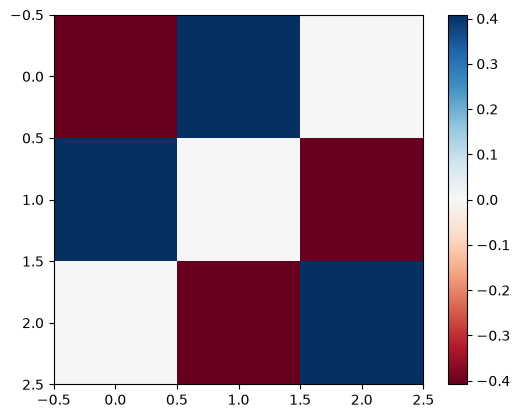

In [5]:
plt.imshow(Vt[-1,:].reshape(shape), cmap="RdBu") # Espaço nulo do modelo
plt.colorbar()

## Regularização por suavidade

In [6]:
# Vamos construir a matriz L separadamente
# Lx
Lx = np.zeros((shape[0] * (shape[1] - 1), true_p.size))
for i in range(shape[0]):
    for j in range(shape[1] - 1):
        k = i * (shape[1] - 1) + j 
        Lx[k, i * shape[1] + j] = -1
        Lx[k, i * shape[1] + j + 1] = 1

# Ly
Ly = np.zeros((shape[1] * (shape[0] - 1), true_p.size))

for i in range(shape[0] - 1):
    for j in range(shape[1]):
        k = i * shape[1] + j 
        Ly[k, i * shape[1] + j] = -1
        Ly[k, i * shape[1] + j + shape[1]] = 1

L = np.vstack((Lx, Ly))
L

array([[-1.,  1.,  0.,  0.,  0.,  0.,  0.,  0.,  0.],
       [ 0., -1.,  1.,  0.,  0.,  0.,  0.,  0.,  0.],
       [ 0.,  0.,  0., -1.,  1.,  0.,  0.,  0.,  0.],
       [ 0.,  0.,  0.,  0., -1.,  1.,  0.,  0.,  0.],
       [ 0.,  0.,  0.,  0.,  0.,  0., -1.,  1.,  0.],
       [ 0.,  0.,  0.,  0.,  0.,  0.,  0., -1.,  1.],
       [-1.,  0.,  0.,  1.,  0.,  0.,  0.,  0.,  0.],
       [ 0., -1.,  0.,  0.,  1.,  0.,  0.,  0.,  0.],
       [ 0.,  0., -1.,  0.,  0.,  1.,  0.,  0.,  0.],
       [ 0.,  0.,  0., -1.,  0.,  0.,  1.,  0.,  0.],
       [ 0.,  0.,  0.,  0., -1.,  0.,  0.,  1.,  0.],
       [ 0.,  0.,  0.,  0.,  0., -1.,  0.,  0.,  1.]])

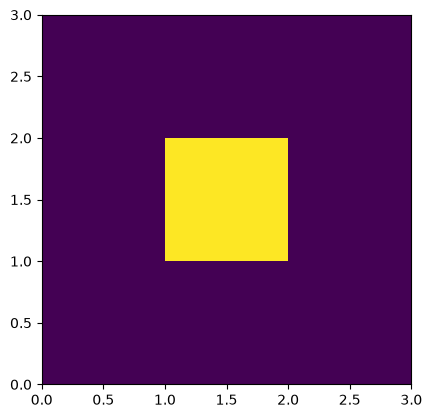

In [7]:
lamb = 1e-10
data = G @ true_p
data += np.random.default_rng().normal(0, 0.001 * np.abs(data).max(), data.size)
p_smooth = np.linalg.solve(G.T @ G + lamb * L.T @ L, G.T @ data)

plt.imshow(p_smooth.reshape(shape), extent=region)

## Exemplo maior

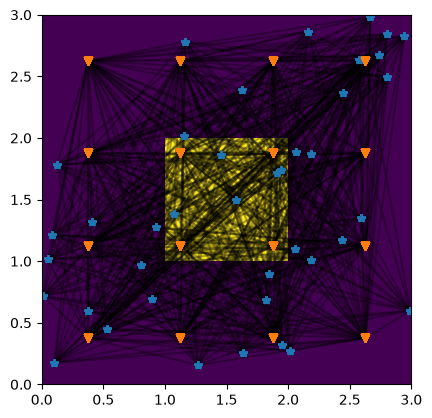

In [8]:
region = [0, 3, 0, 3]
spacing = 0.1
grid = bd.grid_coordinates(region, spacing=spacing, pixel_register=True)
shape = grid[0].shape
true_p = np.ones(shape)
true_p[10:20, 10:20] = 4
true_p = true_p.ravel()
sources = bd.random_coordinates(region, 40, random_seed=0)
recivers = [i.ravel() for i in bd.grid_coordinates(region, spacing=0.75, pixel_register=True)]
sources, recivers = srtomo.pair(sources, recivers)

plt.imshow(true_p.reshape(shape), extent=region)
plt.plot(sources[0], sources[1], '*')
plt.plot(recivers[0], recivers[1], 'v')
srtomo.plot_ray_paths(sources, recivers, zorder=0, alpha=0.3)

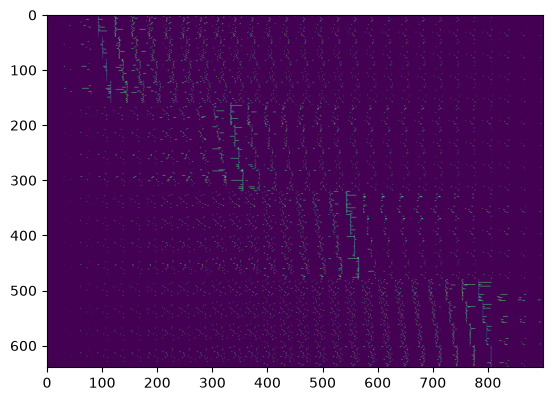

In [16]:
G = srtomo.jacobian(sources, recivers, grid)
plt.imshow(G)

In [17]:
# Vamos construir a matriz L separadamente
# Lx
Lx = np.zeros((shape[0] * (shape[1] - 1), true_p.size))
for i in range(shape[0]):
    for j in range(shape[1] - 1):
        k = i * (shape[1] - 1) + j 
        Lx[k, i * shape[1] + j] = -1
        Lx[k, i * shape[1] + j + 1] = 1

# Ly
Ly = np.zeros((shape[1] * (shape[0] - 1), true_p.size))

for i in range(shape[0] - 1):
    for j in range(shape[1]):
        k = i * shape[1] + j 
        Ly[k, i * shape[1] + j] = -1
        Ly[k, i * shape[1] + j + shape[1]] = 1

L = np.vstack((Lx, Ly))
L

array([[-1.,  1.,  0., ...,  0.,  0.,  0.],
       [ 0., -1.,  1., ...,  0.,  0.,  0.],
       [ 0.,  0., -1., ...,  0.,  0.,  0.],
       ...,
       [ 0.,  0.,  0., ...,  1.,  0.,  0.],
       [ 0.,  0.,  0., ...,  0.,  1.,  0.],
       [ 0.,  0.,  0., ...,  0.,  0.,  1.]], shape=(1740, 900))

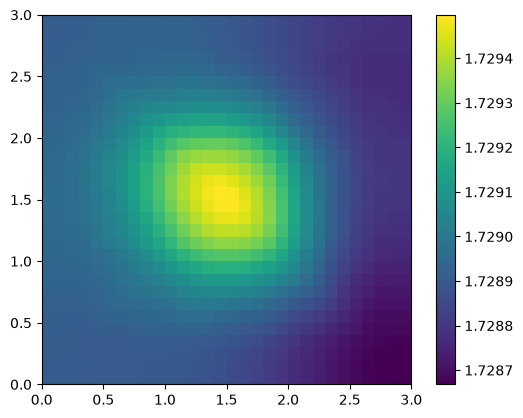

In [22]:
lamb = 1e5
data = G @ true_p
data += np.random.default_rng().normal(0, 0.001 * np.abs(data).max(), data.size)
p_smooth = np.linalg.solve(G.T @ G + lamb * L.T @ L, G.T @ data)
#p_smooth = np.linalg.solve(G.T @ G + lamb * np.identity(true_p.size), G.T @ data)

plt.imshow(p_smooth.reshape(shape), extent=region)
plt.colorbar()

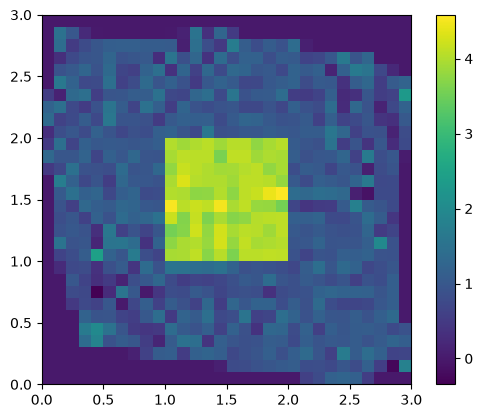

In [36]:
lamb = 1e-5
data = G @ true_p
data += np.random.default_rng().normal(0, 0.001 * np.abs(data).max(), data.size)
p_smooth = np.linalg.solve(G.T @ G + lamb * np.identity(true_p.size), G.T @ data)

plt.imshow(p_smooth.reshape(shape), extent=region)
plt.colorbar()